# Inspect the crops

Where every training crop comes from, drawn on the boards it was cut from. Uses the manifests written by `preprocess_walkthrough.ipynb`; nothing is written or changed.

| Part | Shows |
|---|---|
| 1 | **256×256 defect-free crops** on the whole board: positions, coverage, crops replaced by the repair step |
| 2 | **64×64 defect patches** on the defect photo: the label box, the crop window, and the saved patch, including the oversized boxes that were rescaled |

Change `BOARD` and `PHOTO` in the settings cell and rerun the part you want. Runs on CPU.

In [1]:
%matplotlib inline
import random
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "third_party" / "CRG-DefectDiffuser").is_dir())
PKU = ROOT / "data" / "PKU-Market-PCB-corrected"
PROC = ROOT / "data" / "pcb_processed"
SCALE, PATCH, FREE = 0.5, 64, 256

free = pd.read_csv(PROC / "free_manifest.csv")
free["board"] = free["source"].str[:2]
check = pd.read_csv(PROC / "free_check.csv") if (PROC / "free_check.csv").exists() else None
if check is not None:
    free = free.merge(check[["file", "status", "old_source"]], on="file", how="left")
defect = pd.read_csv(PROC / "defect_manifest.csv")
defect["board"] = defect["source"].str[:2]
defect["rescaled"] = defect["window"] > PATCH
in_50pc = {p.name for p in (PROC / "defect_64_50pc").glob("*.jpg")}
defect["in_50pc"] = defect["file"].isin(in_50pc)
CLASSES = ["missinghole", "mousebite", "opencircuit", "short", "spur", "spuriouscopper"]
COLORS = dict(zip(CLASSES, plt.cm.tab10.colors))
print(f"free_256: {len(free)} crops on boards {sorted(free.board.unique())}")
print(f"defect_64: {len(defect)} patches · rescaled {defect.rescaled.sum()} · in the 50/class subset {defect.in_50pc.sum()}")

free_256: 3000 crops on boards ['01', '04', '05', '06', '07', '08', '09']
defect_64: 2185 patches · rescaled 115 · in the 50/class subset 300


## Settings

In [ ]:
BOARD = "01"                 # 第 1 部分：查看哪块板（01, 04, 05, 06, 07, 08, 09）
PHOTO = "01_short_17"        # 第 2 部分：查看哪张缺陷照片（文件名不带 .jpg）
N_SHOW = 8                   # 显示多少张裁剪的缩略图
SEED = 0

In [3]:
def scaled_photo(stem):
    """与预处理相同：整张照片双三次缩放到 0.5×"""
    im = Image.open(PKU / "images" / f"{stem}.jpg").convert("RGB")
    return im.resize((round(im.width * SCALE), round(im.height * SCALE)), Image.BICUBIC)


def label_boxes(stem, w, h):
    """YOLO 标注转换为 0.5× 图像上的像素框 (类别名, x0, y0, x1, y1)"""
    out = []
    for line in (PKU / "labels" / f"{stem}.txt").read_text().splitlines():
        c, cx, cy, bw, bh = map(float, line.split())
        out.append((CLASSES[int(c)], (cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h))
    return out


def template(board):
    return Image.open(PROC / "templates" / f"board_{board}.png").convert("RGB")


def rect(ax, x, y, w, h, **kw):
    ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, **kw))

## Part 1 · 256×256 defect-free crops on the board

### All boards at once

Left of each pair: every crop window on the clean board image (green; orange = replaced by the repair step, now cut from another photo at the same position). Right: how many crops cover each pixel. All photos of a board are aligned copies of one image, so crops from different photos of the same board can be drawn on one board image. The darker band along the edges is expected: an edge pixel can only be inside crops that lie towards the centre, and crops stay 32 px from the photo edge.

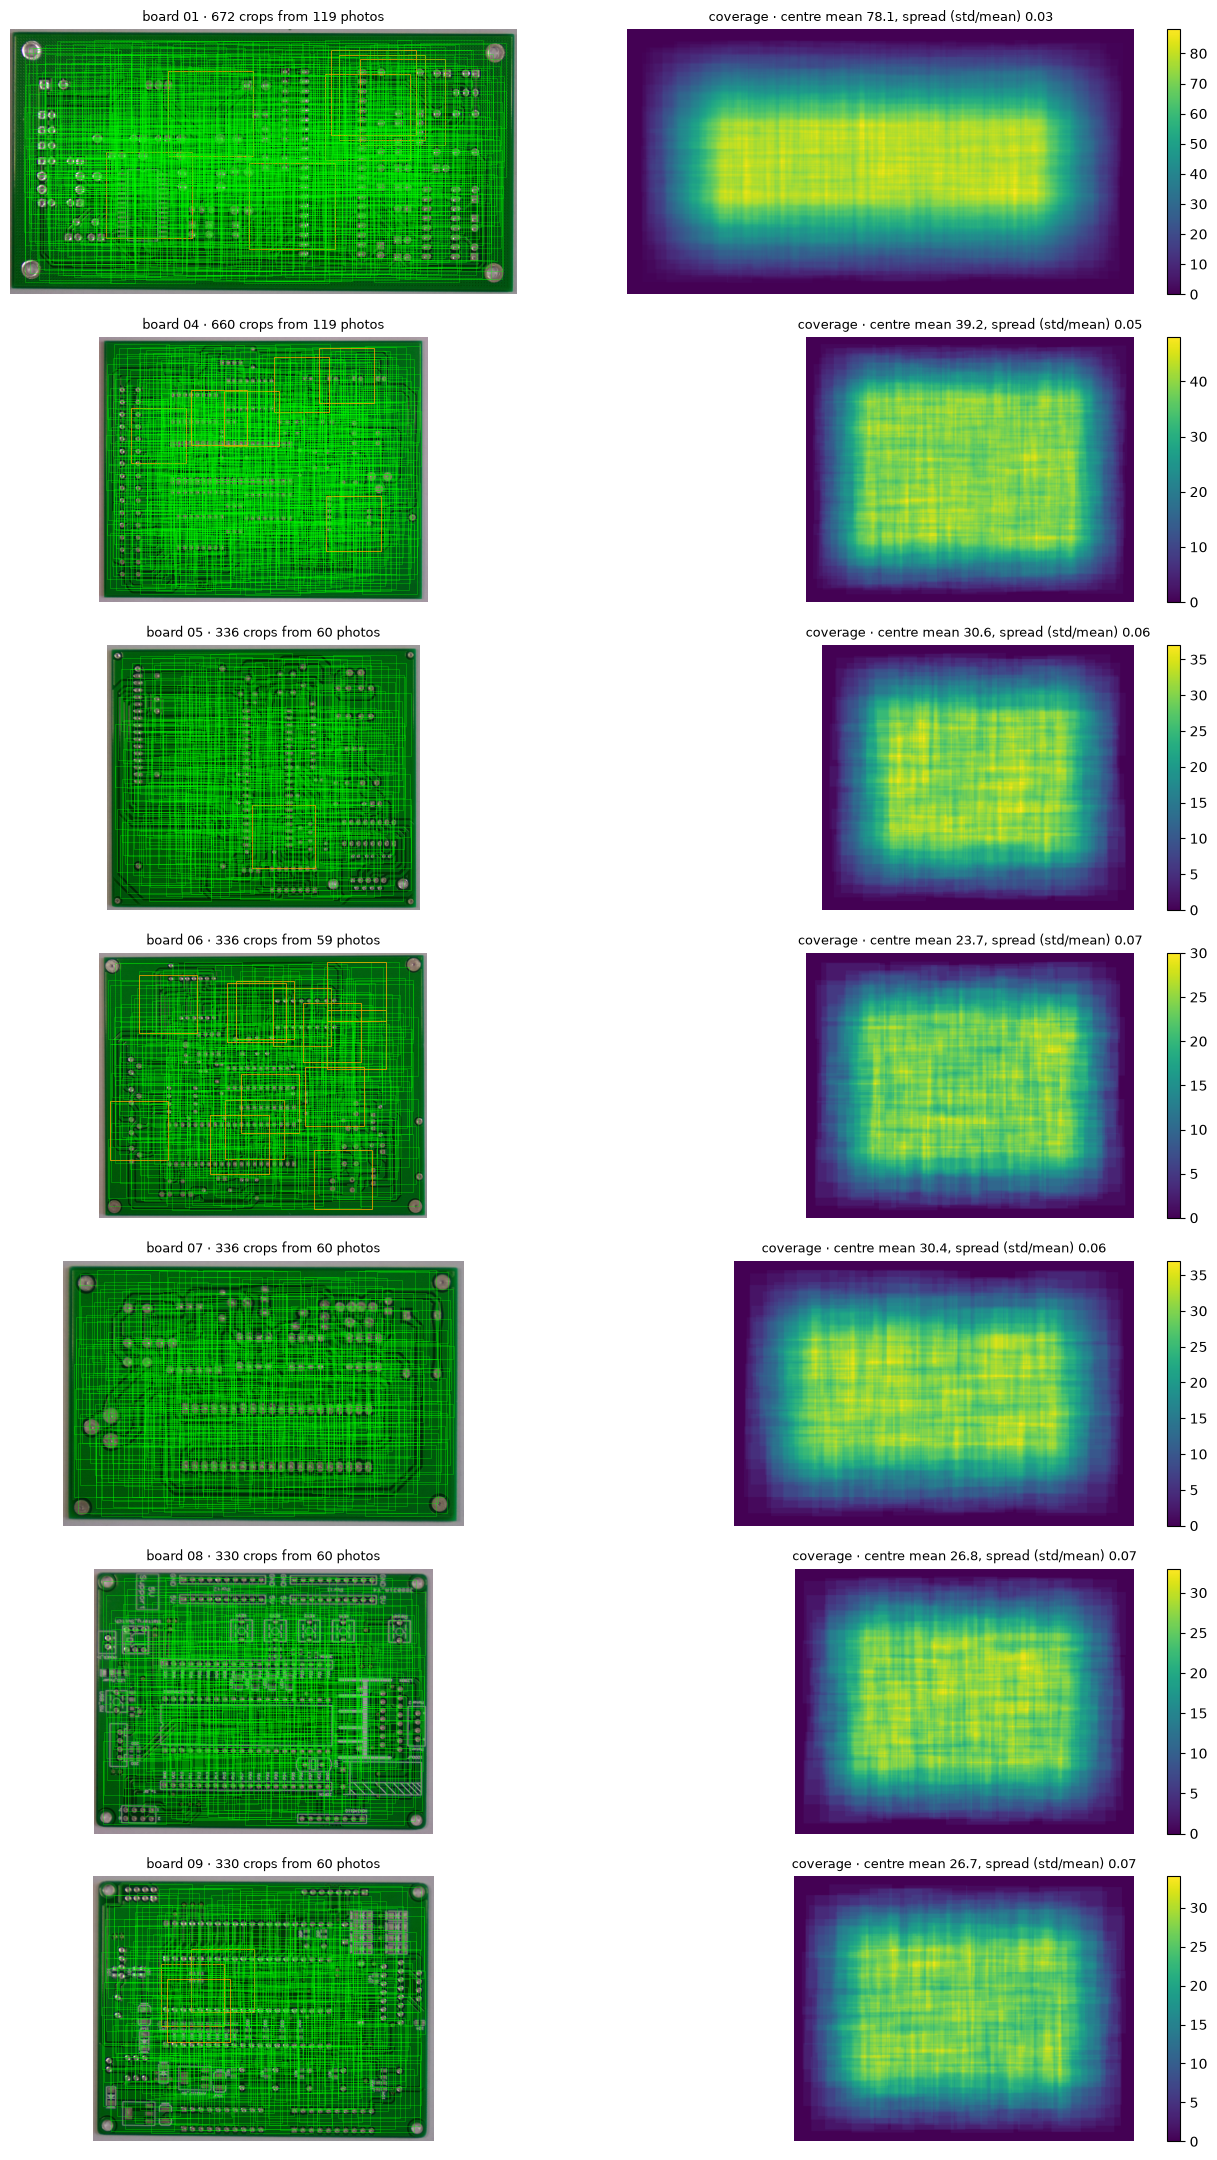

In [4]:
boards = sorted(free.board.unique())
fig, axes = plt.subplots(len(boards), 2, figsize=(13, 3.1 * len(boards)))
for r, b in enumerate(boards):
    tpl = template(b); w, h = tpl.size
    sub = free[free.board == b]
    cov = np.zeros((h, w), np.int32)
    axes[r, 0].imshow(tpl)
    for _, c in sub.iterrows():
        cov[c.top:c.top + FREE, c.left:c.left + FREE] += 1
        replaced = check is not None and c.status == "replaced"
        rect(axes[r, 0], c.left, c.top, FREE, FREE, ec="orange" if replaced else "lime", lw=0.6, alpha=0.9 if replaced else 0.35)
    im = axes[r, 1].imshow(cov, cmap="viridis")
    plt.colorbar(im, ax=axes[r, 1], fraction=0.025)
    inner = cov[32 + FREE:h - 32 - FREE, 32 + FREE:w - 32 - FREE]
    axes[r, 0].set_title(f"board {b} · {len(sub)} crops from {sub.source.nunique()} photos", fontsize=9)
    axes[r, 1].set_title(f"coverage · centre mean {inner.mean():.1f}, spread (std/mean) {inner.std() / inner.mean():.2f}", fontsize=9)
    for a in axes[r]:
        a.set_axis_off()
plt.tight_layout(); plt.show()

### One board in detail

The chosen board with every crop window numbered by its file, and thumbnails of a few crops. The numbers in the thumbnail titles match the numbers on the board.

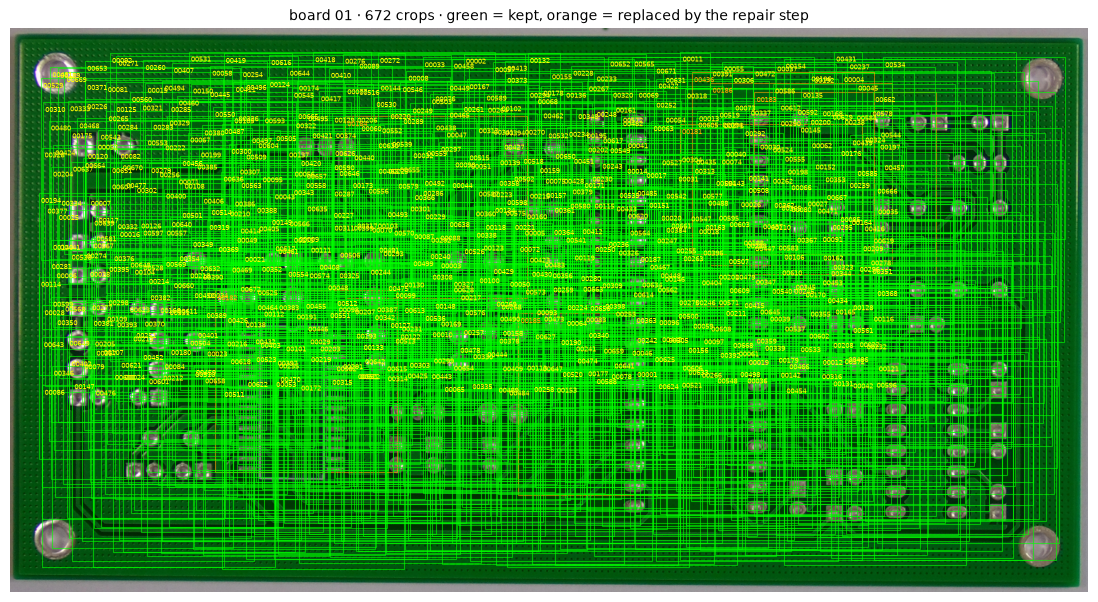

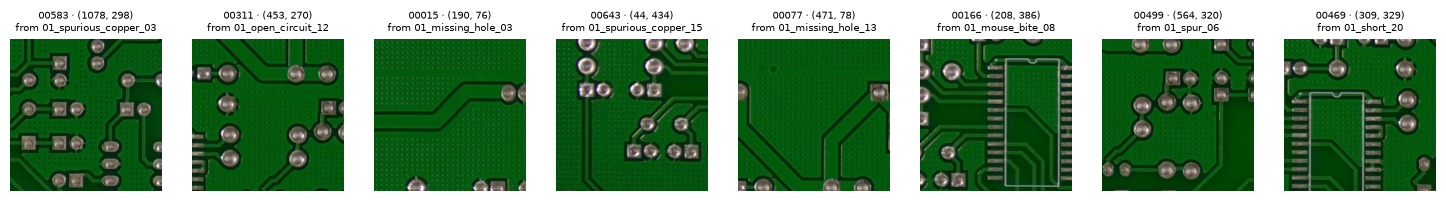

,count,mean,std,min,25%,50%,75%,max
crops per photo,119.0,5.6,0.6,4.0,5.0,6.0,6.0,7.0


In [5]:
sub = free[free.board == BOARD].reset_index(drop=True)
tpl = template(BOARD)
fig, ax = plt.subplots(figsize=(14, 14 * tpl.height / tpl.width))
ax.imshow(tpl)
for _, c in sub.iterrows():
    replaced = check is not None and c.status == "replaced"
    rect(ax, c.left, c.top, FREE, FREE, ec="orange" if replaced else "lime", lw=0.8, alpha=0.6)
    ax.text(c.left + 3, c.top + 14, c.file[5:10], fontsize=5, color="yellow" if not replaced else "orange")
ax.set_axis_off()
ax.set_title(f"board {BOARD} · {len(sub)} crops · green = kept, orange = replaced by the repair step", fontsize=10)
plt.show()

pick = sub.sample(min(N_SHOW, len(sub)), random_state=SEED)
fig, axes = plt.subplots(1, len(pick), figsize=(2.3 * len(pick), 2.7))
for a, (_, c) in zip(np.atleast_1d(axes), pick.iterrows()):
    a.imshow(Image.open(PROC / "free_256" / c.file)); a.set_axis_off()
    a.set_title(f"{c.file[5:10]} · ({c.left}, {c.top})\nfrom {c.source}", fontsize=7)
plt.show()
display(sub.groupby("source").size().describe().to_frame("crops per photo").T.round(1))

## Part 2 · 64×64 defect patches on the defect photo

### One photo in detail

Red = label box. Yellow = 64×64 window cut directly at 0.5×. Magenta = enlarged window for a box longer than 64 px, resized down to 64×64. Below: the window as it is on the photo and the patch that was saved, with its effective scale relative to the original photo (0.5 for normal patches).

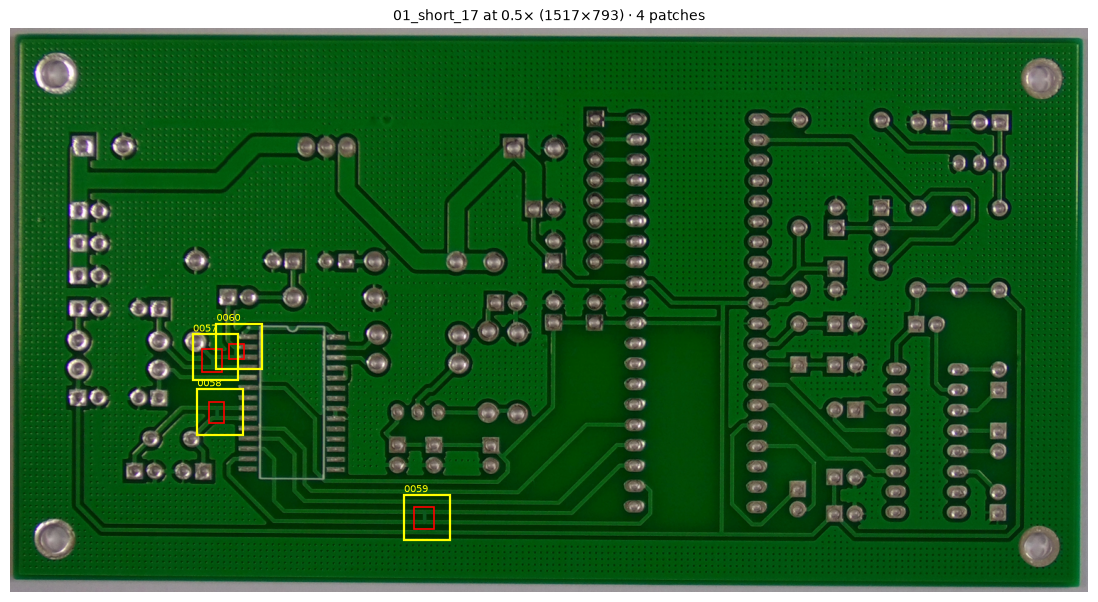

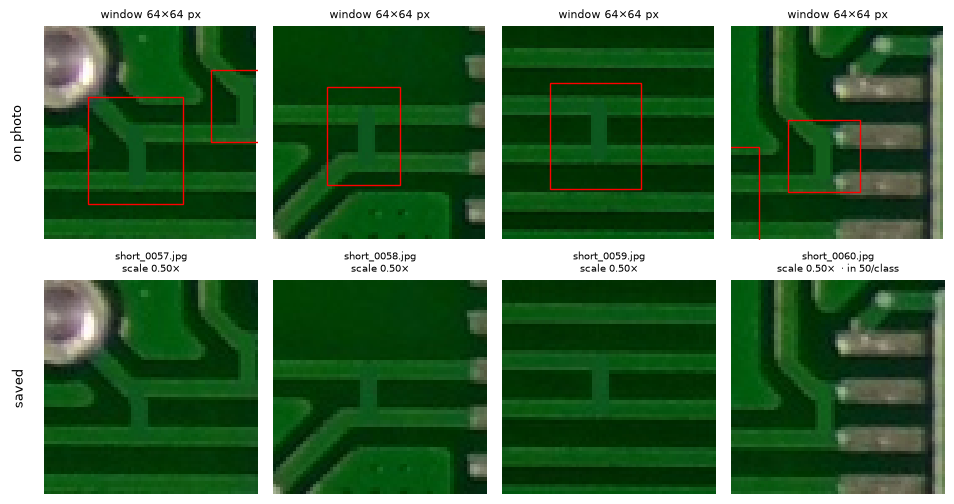

In [6]:
ph = scaled_photo(PHOTO); w, h = ph.size
rows = defect[defect.source == PHOTO].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, 14 * h / w))
ax.imshow(ph)
for name, x0, y0, x1, y1 in label_boxes(PHOTO, w, h):
    rect(ax, x0, y0, x1 - x0, y1 - y0, ec="red", lw=1.2)
for _, r in rows.iterrows():
    rect(ax, r.left, r.top, r.window, r.window, ec="magenta" if r.rescaled else "yellow", lw=1.6)
    ax.text(r.left, r.top - 4, r.file.split("_")[1][:4], fontsize=7, color="yellow")
ax.set_axis_off()
ax.set_title(f"{PHOTO} at 0.5× ({w}×{h}) · {len(rows)} patches", fontsize=10)
plt.show()

if len(rows):
    fig, axes = plt.subplots(2, len(rows), figsize=(2.4 * len(rows), 5.2), squeeze=False)
    for k, r in rows.iterrows():
        win = ph.crop((r.left, r.top, r.left + r.window, r.top + r.window))
        axes[0, k].imshow(win, interpolation="nearest")
        for name, x0, y0, x1, y1 in label_boxes(PHOTO, w, h):    # 窗口内的标注框
            rect(axes[0, k], x0 - r.left, y0 - r.top, x1 - x0, y1 - y0, ec="red", lw=1)
        axes[0, k].set_xlim(0, r.window); axes[0, k].set_ylim(r.window, 0)
        axes[0, k].set_title(f"window {r.window}×{r.window} px", fontsize=8)
        axes[1, k].imshow(Image.open(PROC / "defect_64" / r.file), interpolation="nearest")
        axes[1, k].set_title(f"{r.file}\nscale {r.effective_scale:.2f}×{'  · in 50/class' if r.in_50pc else ''}", fontsize=7)
        axes[0, k].set_axis_off(); axes[1, k].set_axis_off()
    axes[0, 0].text(-6, rows.window[0] / 2, "on photo", rotation=90, ha="right", va="center", fontsize=9)
    axes[1, 0].text(-6, 32, "saved", rotation=90, ha="right", va="center", fontsize=9)
    plt.tight_layout(); plt.show()

### All defect windows of one board

All photos of a board are aligned, so the windows of every photo of `BOARD` can be drawn on its clean board image, coloured by class. This shows where defects were placed on the board and which areas the defect model sees.

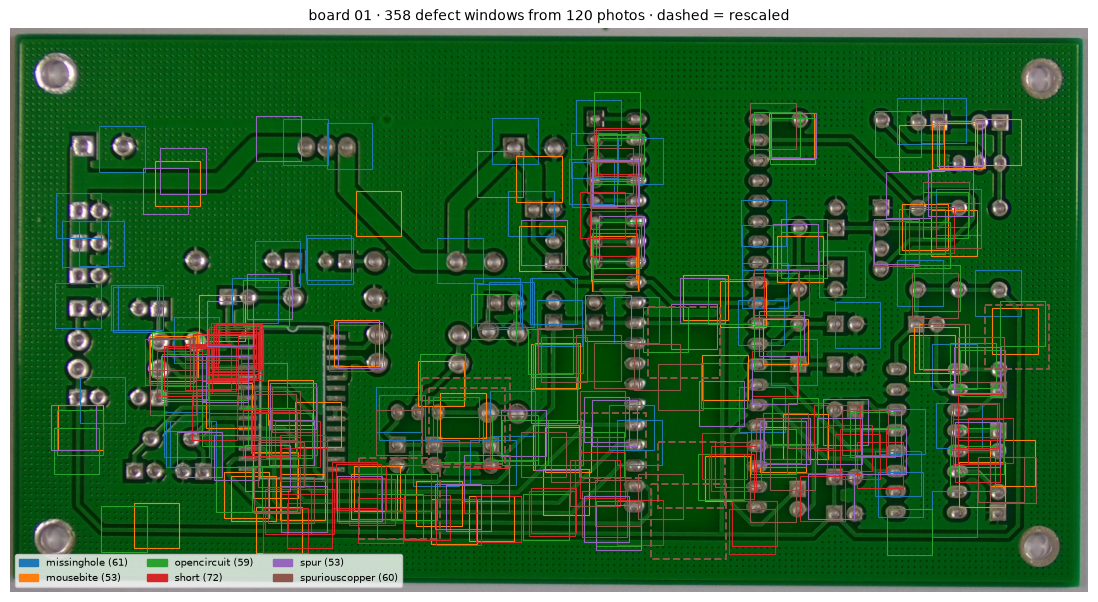

In [7]:
tpl = template(BOARD)
sub = defect[defect.board == BOARD]
fig, ax = plt.subplots(figsize=(14, 14 * tpl.height / tpl.width))
ax.imshow(tpl)
for _, r in sub.iterrows():
    rect(ax, r.left, r.top, r.window, r.window, ec=COLORS[r["class"]], lw=1.4 if r.rescaled else 0.8,
         ls="--" if r.rescaled else "-")
ax.legend(handles=[mpatches.Patch(color=COLORS[c], label=f"{c} ({(sub['class'] == c).sum()})") for c in CLASSES],
          loc="lower left", fontsize=7, ncol=3)
ax.set_axis_off()
ax.set_title(f"board {BOARD} · {len(sub)} defect windows from {sub.source.nunique()} photos · dashed = rescaled", fontsize=10)
plt.show()

### The rescaled patches

Boxes longer than 64 px at 0.5× get a larger window that is resized to 64×64, so these patches are at a smaller scale than the rest. Histogram of their effective scale, and pairs of window (left) and saved patch (right).

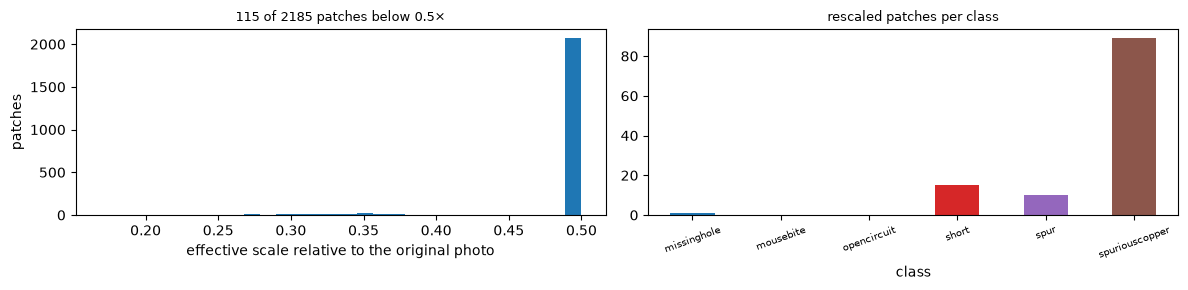

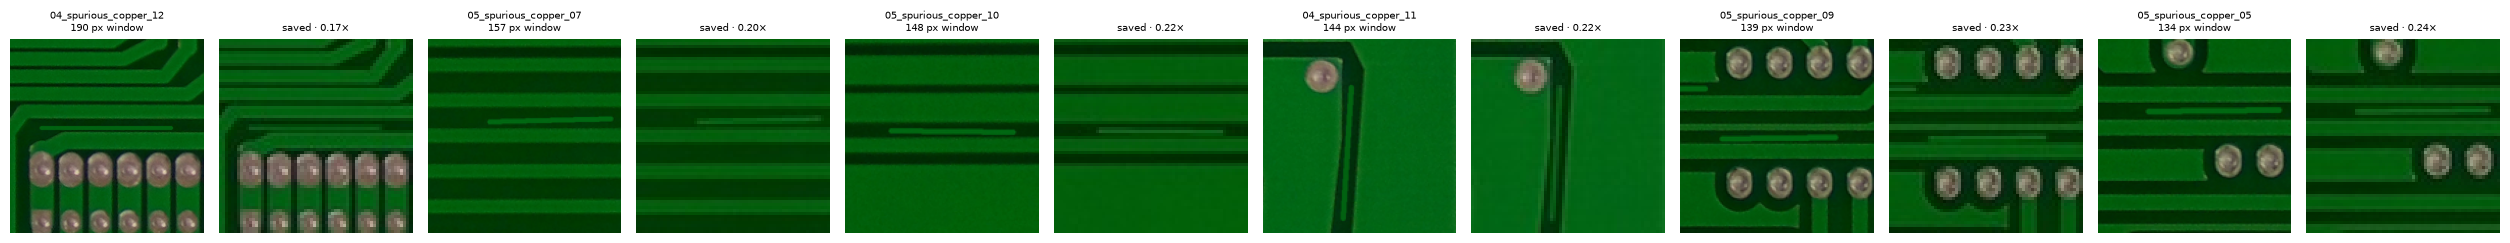

In [8]:
rs = defect[defect.rescaled].sort_values("window", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].hist(defect.effective_scale, bins=30, color="tab:blue")
axes[0].set_xlabel("effective scale relative to the original photo"), axes[0].set_ylabel("patches")
axes[0].set_title(f"{len(rs)} of {len(defect)} patches below 0.5×", fontsize=9)
rs["class"].value_counts().reindex(CLASSES, fill_value=0).plot.bar(ax=axes[1], color=[COLORS[c] for c in CLASSES])
axes[1].set_title("rescaled patches per class", fontsize=9); axes[1].tick_params(axis="x", labelsize=7, rotation=20)
plt.tight_layout(); plt.show()

show = rs.head(6)
fig, axes = plt.subplots(1, 2 * len(show), figsize=(2.1 * 2 * len(show), 2.6))
for k, (_, r) in enumerate(show.iterrows()):
    ph = scaled_photo(r.source)
    axes[2 * k].imshow(ph.crop((r.left, r.top, r.left + r.window, r.top + r.window)))
    axes[2 * k].set_title(f"{r.source}\n{r.window} px window", fontsize=7)
    axes[2 * k + 1].imshow(Image.open(PROC / "defect_64" / r.file), interpolation="nearest")
    axes[2 * k + 1].set_title(f"saved · {r.effective_scale:.2f}×", fontsize=7)
for a in axes:
    a.set_axis_off()
plt.tight_layout(); plt.show()